# Unconfirmed TESS candidates at very small $a/R_\star$

The unconfirmed rocky TOIs (TFOPWG disposition PC, $R_p < 2\,R_\oplus$) with $a/R_\star < 3$ in the ExoFOP / NASA Exoplanet Archive TOI table (2026-10-20): TOI-7715.01, TOI-539.01, TOI-4644.01 and TOI-1242.01. Their geometry is derived from the catalogue, which has no $a/R_\star$, and each runs through the standard analysis next to the known record holders TOI-2431 b and K2-141 b (tinted axes). The candidates have no noise level, so they carry no error bars. Sections 5 and 6 take several minutes.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from dataclasses import replace
from astropy import constants as const
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle the SPIDERMAN workers between planets
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperphase.defaults import (A_B_FIT_BOUNDS, DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U,
                                 DEFAULT_U_BOL)
from hyperphase.planet import PlanetParams
from hyperphase.model import ConstantBandAlbedo, FittingConfig, model_pcurve
from hyperphase.phasecurve import nightside_flux
from hyperphase.bands import filter_lambda, FILTER_LAMBDA_UM, filter_loc, PANDEXO_MODES
from hyperphase.roche import G_CGS, ROCHE_CASES, roche_proximity
from hyperphase.bias.detectors import detectors
from hyperphase.bias.fisher import fisher_sigma
from hyperphase.bias.fits import fit_naive, fit_redist
from hyperphase.bias.maps import roche_periods
from hyperphase.bias.tables import instrument_retrievals
from hyperphase.parallel import pmap
from hyperphase.plotting.bias import plot_fit_vs_truth, plot_instrument_retrievals
from hyperphase.plotting.style import AXIS, C_HI, C_NAIVE, C_REDIST, INK, MUTED, set_plot_style
from hyperphase.targets import DEFAULT_W_DEG, hi_planets_by_name
from hyperphase.plotting.bias import _param_rows   # the rows of numbers under an axis, as in plot_false_F_bars / plot_planet_bias_bars (not exported by *)
from hyperphase.noise import NoNoiseLevelError, rms_1min
from hyperphase.paper import JWST_RETRIEVALS


def show_table(df, index="name"):
    '''A wide table transposed (quantities as rows, planets as columns) and formatted, so it renders in the notebook instead of wrapping.'''
    fmt = lambda v: "-" if v is None or (isinstance(v, float) and not np.isfinite(v)) else (f"{v:.4g}" if isinstance(v, (float, np.floating)) else v)
    t = df.set_index(index).T if index in df else df.T
    display(t.map(fmt) if hasattr(t, "map") else t.applymap(fmt))

## 1. Literature parameters

One dict per candidate, every value a catalogue number of the ExoFOP TOI table (downloaded 2026-10-20): period, $T_{14}$, depth and radius from the TESS SPOC or QLP alert fit, the host from TIC v8 (Stassun et al. 2019), with the catalogue's uncertainties. Two caveats:

- TIC $\log g$ and $M_\star$ are not measured but derived from $T_{\rm eff}$ and the Gaia-parallax radius, so $a/R_\star$ below rests on the TIC's mass and inherits its error ($\pm 0.34$ dex in $\log g$ for TOI-539.01).
- The catalogue planet radius can be stale (TOI-2431.01 is listed with $5.6\,R_\oplus$ while its own depth and $R_\star$ give $1.7$), so $R_p/R_\star$ is taken from the depth.

`kmag_est` is a $K$ magnitude estimated from the TESS magnitude and $T_{\rm eff}$ (not 2MASS, not used here): the normalisation a PandExo run for the candidate would need.

In [2]:
EXOFOP_DATE = "2026-10-20"   # download date of the ExoFOP TOI table every catalogue value below comes from

# TOI-7715.01 -- TIC 200001699. Alerted 2026-04-09 from a single sector (98, SPOC), the youngest and least followed-up candidate. ExoFOP: "potential multi; potential USP", TFOP master priority 1, 1 spectrum, no imaging, no ground photometry yet.
TOI_7715_01 = dict(
    name="TOI-7715.01", tic=200001699, disposition="PC",   # TFOPWG disposition
    period_d=0.323632,      period_d_err=0.000011,     # [d] SPOC transit fit (7.77 h)
    t14_h=0.946561,         t14_h_err=0.098669,        # [h] total transit duration, SPOC; +-10 %
    depth_ppm=488.04,       depth_ppm_err=39.96,       # [ppm] SPOC; +-8 %, i.e. +-4 % on Rp/R*
    r1_earth_cat=1.5427,    r1_earth_cat_err=0.5291,   # [R_earth] catalogue planet radius; +-34 %. Comparison only, r1 comes from the depth
    teff_K=4006.0,          teff_K_err=121.4,          # [K] TIC v8 (Gaia photometry)
    logg=4.58673,           logg_err=0.114836,         # [cgs] TIC v8, derived from M* and R* (see 1.)
    r2_rsun=0.668868,       r2_rsun_err=0.067176,      # [R_sun] TIC v8 (Gaia parallax + bolometric correction); +-10 %
    mstar_msun=0.63,        mstar_msun_err=0.077,      # [M_sun] TIC v8 Teff-mass relation; not used (log g carries it)
    met=None,                                          # [Fe/H] none in the catalogue
    dist_pc=57.00, tmag=10.640,                        # TIC v8
    kmag_est=8.61,          kmag_est_err=0.11,         # [mag] estimated from T mag and Teff (see 1.), NOT 2MASS; not used
)

# TOI-539.01 -- TIC 238004786. Alerted 2019-02-26 (sector 2), SPOC multisector fit over 13 sectors (1-65): best ephemeris of the set. ExoFOP: "a/Rs ~2; possibly evaporating", master priority 1, 9 ground light curves, 2 spectra, 3 imaging observations and still PC after 7 years.
TOI_539_01 = dict(
    name="TOI-539.01", tic=238004786, disposition="PC",
    period_d=0.309606,      period_d_err=0.000004,     # [d] SPOC multisector (7.43 h)
    t14_h=1.029893,         t14_h_err=0.164736,        # [h] +-16 %
    depth_ppm=257.71,       depth_ppm_err=14.78,       # [ppm] +-6 %
    r1_earth_cat=1.5527,    r1_earth_cat_err=0.3109,   # [R_earth] comparison only
    teff_K=4836.0,          teff_K_err=178.0,          # [K] TIC v8
    logg=4.44968,           logg_err=0.343852,         # [cgs] TIC v8; the largest log g error of the set -> +-26 % on a/R*
    r2_rsun=0.813125,       r2_rsun_err=0.053133,      # [R_sun] TIC v8; +-7 %
    mstar_msun=0.80,        mstar_msun_err=0.098,      # [M_sun] TIC v8; not used
    met=None,
    dist_pc=108.37, tmag=10.596,
    kmag_est=9.07,          kmag_est_err=0.11,
)

# TOI-4644.01 -- TIC 387423096. Alerted 2021-11-19 (QLP, sectors 42-44). ExoFOP: "small a/Rs; possibly variability; v-shaped" (the V shape is the false-positive risk: high b or a blend), master priority 2, 8 imaging observations, 2 spectra, no ground photometry.
TOI_4644_01 = dict(
    name="TOI-4644.01", tic=387423096, disposition="PC",
    period_d=0.318185,      period_d_err=0.000018,     # [d] QLP (7.64 h)
    t14_h=0.762,            t14_h_err=0.172,           # [h] +-23 %
    depth_ppm=480.0,        depth_ppm_err=2.58,        # [ppm] QLP; the quoted +-0.5 % is not credible at SNR 15 -- treat as a few %
    r1_earth_cat=1.7823,    r1_earth_cat_err=0.2293,   # [R_earth] comparison only
    teff_K=4242.23,         teff_K_err=142.3,          # [K] TIC v8
    logg=4.5065,            logg_err=0.119222,         # [cgs] TIC v8
    r2_rsun=0.75,           r2_rsun_err=0.08,          # [R_sun] TIC v8; +-11 %
    mstar_msun=0.66,        mstar_msun_err=0.080,      # [M_sun] TIC v8; not used
    met=-0.108,                                        # [Fe/H] TIC v8 (the only candidate with one), +-0.032
    dist_pc=88.78, tmag=11.051,
    kmag_est=9.17,          kmag_est_err=0.11,
)

# TOI-1242.01 -- TIC 198212955. Alerted 2019-10-17, SPOC over 17 sectors (northern CVZ, so also in JWST's). ExoFOP: "Possible L1 candidate; very short period", master priority 1, SNR 27, 10 ground light curves, 4 spectra, 6 imaging observations, still PC. Radius straddles the rocky cut (1.85 R_earth from the depth, 2.06 in the catalogue).
TOI_1242_01 = dict(
    name="TOI-1242.01", tic=198212955, disposition="PC",
    period_d=0.381485,      period_d_err=0.000001,     # [d] SPOC multisector (9.16 h)
    t14_h=0.565,            t14_h_err=0.154,           # [h] +-27 %; the shortest duration of the set -> b ~ 0.9
    depth_ppm=570.0,        depth_ppm_err=4.70,        # [ppm] SPOC; quoted +-0.8 %
    r1_earth_cat=2.0605,    r1_earth_cat_err=0.2555,   # [R_earth] comparison only; 11 % above the depth-based radius, i.e. fitted with an older, larger TIC R*
    teff_K=4255.0,          teff_K_err=128.2,          # [K] TIC v8
    logg=4.55641,           logg_err=0.106625,         # [cgs] TIC v8
    r2_rsun=0.71,           r2_rsun_err=0.07,          # [R_sun] TIC v8; +-10 %
    mstar_msun=0.665,       mstar_msun_err=0.083,      # [M_sun] TIC v8; not used
    met=None,
    dist_pc=110.02, tmag=11.598,
    kmag_est=9.73,          kmag_est_err=0.11,
)

CANDIDATES = [TOI_7715_01, TOI_539_01, TOI_4644_01, TOI_1242_01]

# The TOI-table rows of the two known planets, SAME columns and source, used only to validate the derivations of 2. against the published values (the analysis uses hi_planets_by_name for them).
TOI_2431_01 = dict(   # TOI-2431 b, TIC 258804746, CP. Published (Tas et al. 2026, archive): a/R* = 2.081, Rp/R* = 0.02131, i = 74.0 deg. The TOI row is poor: depth 540 +- 636 ppm, pl_rade 5.6 R_earth.
    name="TOI-2431.01 (TOI row)", tic=258804746, disposition="CP",
    period_d=0.224195, period_d_err=None, t14_h=0.292, t14_h_err=0.026, depth_ppm=540.0, depth_ppm_err=636.2, r1_earth_cat=5.5955, r1_earth_cat_err=1.955,
    teff_K=4079.0, teff_K_err=126.0, logg=4.58, logg_err=0.11, r2_rsun=0.68, r2_rsun_err=0.07, mstar_msun=0.64, mstar_msun_err=0.078, met=None, dist_pc=36.06, tmag=9.521, kmag_est=None, kmag_est_err=None,
)
TOI_6835_01 = dict(   # K2-141 b, TIC 301235044, KP. Published (Malavolta et al. 2018, Barragan et al. 2018; the CUSTOM entry): a/R* = 2.292, Rp/R* = 0.02037, i = 86.3 deg, T14 = 0.94 h.
    name="TOI-6835.01 (TOI row)", tic=301235044, disposition="KP",
    period_d=0.280325, period_d_err=None, t14_h=0.868, t14_h_err=0.134, depth_ppm=507.0, depth_ppm_err=32.0, r1_earth_cat=1.6483, r1_earth_cat_err=0.1457,
    teff_K=4477.0, teff_K_err=124.7, logg=4.56, logg_err=0.10, r2_rsun=0.72, r2_rsun_err=0.06, mstar_msun=0.70, mstar_msun_err=0.086, met=None, dist_pc=61.87, tmag=10.030, kmag_est=None, kmag_est_err=None,
)

## 2. Derived quantities

- **$a/R_\star$** from Kepler III and the stellar density: $(a/R_\star)^3 = G\rho_\star P^2/(3\pi)$ with $\rho_\star = 3g/(4\pi G R_\star)$ from the TIC $\log g$ and $R_\star$; $1\sigma$ from $\mathrm{d}\ln(a/R_\star) = \tfrac13(\ln 10\,\mathrm{d}\log g - \mathrm{d}R_\star/R_\star)$. On 365 confirmed TOIs (2026-10-20) derived over published $a/R_\star$ has median 0.98 (16–84 %: 0.91–1.03).
- **$R_p/R_\star = \sqrt{\delta}$** from the depth, without limb darkening: up to ~10 % high for a central transit.
- **$b$ and $i$** from $T_{14}$ (Winn 2010 eq. 14, inverted): loose, since the TOI durations are good to 10–30 %; where $T_{14}$ exceeds a central transit, $i$ falls back to 90°.
- **$a$ in AU** only for the light-travel time (`PlanetParams.a_AU`).
- **Roche check**: the period $P_{\rm R}$ at the Roche limit of an Earth-like planet of the candidate's own radius (`roche_periods`; `06_roche_limit.ipynb` §1) and $a/a_{\rm R} = (P/P_{\rm R})^{2/3}$, which needs no stellar density. A candidate inside it ($a/a_{\rm R} < 1$) is iron-rich or not a planet.
- $e = 0$ (tidally circularised), $\omega = 90°$ (`DEFAULT_W_DEG`).

In [3]:
R_SUN_CM, R_EARTH_CM, AU_CM = const.R_sun.cgs.value, const.R_earth.cgs.value, const.au.cgs.value
ROCHE_EARTH = {"Earth-like": ROCHE_CASES["Earth-like"]}   # Roche check: an Earth-like planet of the candidate's own radius (roche.ROCHE_CASES; 06_roche_limit.ipynb section 1)


def stellar_density(logg, r2_rsun):
    '''Mean stellar density [g/cm^3] from log g (cgs) and R* [R_sun]: rho = 3 g / (4 pi G R*). With the TIC's derived log g this is M* / (4/3 pi R*^3) in disguise.'''
    return 3. * 10. ** logg / (4. * np.pi * G_CGS * r2_rsun * R_SUN_CM)


def a_over_r2_from_density(period_d, rho_star):
    '''a/R* of a circular orbit from P [d] and rho* [g/cm^3]: (a/R*)^3 = G rho* P^2 / (3 pi) (Kepler III, M_p << M*). Inverse of roche.kepler_period_days.'''
    return (G_CGS * rho_star * (period_d * 86400.) ** 2 / (3. * np.pi)) ** (1. / 3.)


def a_over_r2_err(a_over_r2, logg_err, r2_rsun, r2_rsun_err):
    '''1 sigma of a/R* from the catalogue errors: d ln(a/R*) = (ln10 dlogg - dR*/R*) / 3, in quadrature (TIC log g and R* taken as independent, which they are not quite -- an overestimate).'''
    return a_over_r2 * np.sqrt((np.log(10.) / 3. * logg_err) ** 2 + (r2_rsun_err / (3. * r2_rsun)) ** 2)


def r1_over_r2_from_depth(depth_ppm):
    '''Rp/R* = sqrt(depth), no limb darkening (see 2.).'''
    return np.sqrt(depth_ppm * 1e-6)


def a_AU_from(a_over_r2, r2_rsun):
    '''Semi-major axis [AU], for PlanetParams.a_AU only.'''
    return a_over_r2 * r2_rsun * R_SUN_CM / AU_CM


def t14_central_h(period_d, a_over_r2, r1_over_r2):
    '''The longest possible total duration [h], b = 0 (Winn 2010 eq. 14): the catalogue T14 must stay below it.'''
    return period_d / np.pi * np.arcsin((1. + r1_over_r2) / a_over_r2) * 24.


def impact_parameter_from_t14(period_d, t14_h, a_over_r2, r1_over_r2):
    '''b from the total duration of a circular transit, Winn 2010 eq. 14 inverted exactly: s = sin(pi T14 / P), b^2 = [(1 + k)^2 - (a/R*)^2 s^2] / (1 - s^2).
    NaN where T14 exceeds the central-transit duration (b^2 < 0: T14, a/R* or k is off) or b > 1 + k (no transit).'''
    s = np.sin(np.pi * t14_h / 24. / period_d)
    b2 = ((1. + r1_over_r2) ** 2 - (a_over_r2 * s) ** 2) / (1. - s ** 2)
    b = np.sqrt(b2) if b2 >= 0. else np.nan
    return b if b <= 1. + r1_over_r2 else np.nan


def inclination_from_b(b, a_over_r2, fallback=90.):
    '''i [deg] = arccos(b R*/a); the fallback (central transit) where b is NaN.'''
    return float(np.degrees(np.arccos(b / a_over_r2))) if np.isfinite(b) else fallback


def derived(p):
    '''Everything PlanetParams needs from one catalogue dict, plus the 1 sigma of a/R* and the geometry checks (b, central T14, Roche limit, depth-based radius in R_earth).'''
    rho = stellar_density(p["logg"], p["r2_rsun"])
    a_rs = a_over_r2_from_density(p["period_d"], rho)
    k = r1_over_r2_from_depth(p["depth_ppm"])
    b = impact_parameter_from_t14(p["period_d"], p["t14_h"], a_rs, k)
    P_R = next(iter(roche_periods(ROCHE_EARTH, R_p=k * p["r2_rsun"] * R_SUN_CM / R_EARTH_CM).values()))   # [h] Earth-like Roche period at the depth-based radius
    return dict(rho_star=rho, a_over_r2=a_rs, a_over_r2_err=a_over_r2_err(a_rs, p["logg_err"], p["r2_rsun"], p["r2_rsun_err"]), r1_over_r2=k,
                r1_earth=k * p["r2_rsun"] * R_SUN_CM / R_EARTH_CM, a_AU=a_AU_from(a_rs, p["r2_rsun"]), b=b, incl=inclination_from_b(b, a_rs),
                t14_central_h=t14_central_h(p["period_d"], a_rs, k), P_roche_h=P_R, a_over_a_roche=float(roche_proximity(24. * p["period_d"], P_R)))


def planet_from_catalogue(p, incl=None):
    '''PlanetParams from a catalogue dict, in stellar radii (r2 = 1), circular; incl from the catalogue T14 unless given. log g and [Fe/H] (0 where the catalogue has none) feed only the stellar SED.'''
    d = derived(p)
    return PlanetParams(name=p["name"], period=p["period_d"], incl=d["incl"] if incl is None else incl, ecc=0.0, w=DEFAULT_W_DEG,
                        r1=d["r1_over_r2"], r2=1.0, R=d["a_over_r2"], T2_eff=p["teff_K"], a_AU=d["a_AU"], T14=p["t14_h"], logg=p["logg"], feh=0.0 if p.get("met") is None else p["met"])


def custom_entry_line(pl, comment=""):
    '''The planet as one PlanetParams line, for targets.register_planet or a row of inputs/planets/curated_planets.csv (copy-paste).'''
    return (f'"{pl.name}": PlanetParams(name="{pl.name}", period={pl.period:.7f}, incl={pl.incl:.1f}, ecc={pl.ecc:.1f}, w={pl.w:.1f}, r1={pl.r1:.5f}, r2={pl.r2:.1f}, '
            f'R={pl.R:.3f}, T2_eff={pl.T2_eff:.1f}, a_AU={pl.a_AU:.5f}, T14={pl.T14:.3f}, logg={pl.logg:.2f}, feh={pl.feh:+.2f}),' + (f"   # {comment}" if comment else ""))

### 2.1 Validation on the two known planets

The same derivations on the TOI-table rows of TOI-2431 b and K2-141 b, against their published values: $a/R_\star$ within its $1\sigma$ but low by a few per cent (the TIC density is the weak link), $R_p/R_\star$ about 10 % high (no limb darkening), and $i$ too small, because the TOI durations of both planets are shorter than their published geometry implies. The candidates' inclinations carry the same caveat.

In [4]:
comparison = hi_planets_by_name(["TOI-2431 b", "K2-141 b"])   # published geometry (CUSTOM entries)

rows = []
for p, pub in ((TOI_2431_01, comparison["TOI-2431 b"]), (TOI_6835_01, comparison["K2-141 b"])):
    d = derived(p)
    rows.append({"name": pub.name, "TOI row": p["name"], "a/R* derived": d["a_over_r2"], "a/R* +-": d["a_over_r2_err"], "a/R* published": pub.R / pub.r2, "derived / published": d["a_over_r2"] / (pub.R / pub.r2),
                 "Rp/R* derived": d["r1_over_r2"], "Rp/R* published": pub.r1 / pub.r2, "b derived": d["b"], "i derived [deg]": d["incl"], "i published [deg]": pub.incl,
                 "T14 catalogue [h]": p["t14_h"], "T14 central [h]": d["t14_central_h"], "T14 used [h]": pub.T14})
show_table(pd.DataFrame(rows))

name,TOI-2431 b,K2-141 b
TOI row,TOI-2431.01 (TOI row),TOI-6835.01 (TOI row)
a/R* derived,1.969,2.208
a/R* +-,0.1795,0.1803
a/R* published,2.08,2.292
derived / published,0.9468,0.9635
Rp/R* derived,0.02324,0.02252
Rp/R* published,0.02131,0.02037
b derived,0.9814,0.5832
i derived [deg],60.11,74.69
i published [deg],74,86.3


## 3. PlanetParams

The candidates from their dicts and the derivations of 2., the comparison planets from `hi_planets_by_name`. The table gives each candidate's geometry and checks: whether the catalogue $T_{14}$ lies below the central-transit duration (else $i$ = 90°), how far outside the Roche limit it sits ($a/a_{\rm R} > 1$), and the depth-based against the catalogue radius.

In [5]:
candidates = {p["name"]: planet_from_catalogue(p) for p in CANDIDATES}
planets = {**candidates, **comparison}                  # analysis order: the candidates, then the known planets
is_comparison = {nm: nm in comparison for nm in planets}

rows = []
for p in CANDIDATES:
    d, pl = derived(p), candidates[p["name"]]
    rows.append({"name": pl.name, "a/R*": d["a_over_r2"], "a/R* +-": d["a_over_r2_err"], "rho* [g/cm^3]": d["rho_star"], "P_R Earth-like [h]": d["P_roche_h"], "a / a_R": d["a_over_a_roche"],
                 "Rp/R* (depth)": d["r1_over_r2"], "Rp [R_earth] (depth)": d["r1_earth"], "Rp [R_earth] catalogue": p["r1_earth_cat"], "T14 catalogue [h]": p["t14_h"], "T14 central [h]": d["t14_central_h"],
                 "b": d["b"], "i [deg]": d["incl"], "a [AU]": d["a_AU"], "lit fraction [%]": 100 * pl.fraction_illuminated()})
show_table(pd.DataFrame(rows))

name,TOI-7715.01,TOI-539.01,TOI-4644.01,TOI-1242.01
a/R*,2.542,2.082,2.275,2.717
a/R* +-,0.2397,0.5513,0.2234,0.2396
rho* [g/cm^3],2.968,1.781,2.201,2.608
P_R Earth-like [h],3.795,4.077,3.531,3.45
a / a_R,1.612,1.492,1.672,1.917
Rp/R* (depth),0.02209,0.01605,0.02191,0.02387
Rp [R_earth] (depth),1.612,1.424,1.792,1.849
Rp [R_earth] catalogue,1.543,1.553,1.782,2.061
T14 catalogue [h],0.9466,1.03,0.762,0.565
T14 central [h],1.023,1.206,1.132,1.126


## 4. Assumptions shared by every planet

The baseline settings of `hyperphase/defaults.py` for every planet (no albedo is known for any of them), MIRI/LRS for the phase-curve figures and the JWST bands for the per-instrument figures. The known planets get their noise from `noise.rms_1min`; an instrument without a level (K2-141 b on MIRI imaging) is fitted without one. The candidates are not in the archive table PandExo reads, so they get a placeholder noise level and only their noise-independent fitted $A_B$ and $F$ are shown: no error bars, mock data, Fisher $\sigma$, verdicts or $\chi^2$.

In [6]:
u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # transit and irradiance limb darkening (baseline settings, hyperphase/defaults.py)
A_B_true = DEFAULT_A_B           # Bond albedo of every planet; the fits inject and recover this value
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B
A = A_model(A_B_true)

instrument = "MIRI/LRS"          # the phase-curve figures
filter_path = filter_loc(instrument)
l1, l2 = filter_lambda(instrument)
n_bins = DEFAULT_N_BINS          # bins per orbit
n_orbits = DEFAULT_N_ORBITS      # orbits observed; enters only the Fisher sigmas and chi^2 of the known planets

# planet and sigma_1min are replaced per planet in 5. and 6.
cfg = FittingConfig(planet=comparison["TOI-2431 b"], filter_path=filter_path, l1=l1, l2=l2, A_=A_model,
                    sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_bol=u_bol, u=u)
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)   # n_layers is left to the per-model default of pcurve_params
bounds = A_B_FIT_BOUNDS         # A_B range of the fits (below the physical floor 0 allowed)

retrieval_instruments = JWST_RETRIEVALS   # sorted by wavelength; the tuple in it is one joint fit of the two NIRSpec arrays (shared A_B, a baseline per detector)
detectors_all = list(dict.fromkeys(d for ins in retrieval_instruments for d in detectors(ins)))
night_instruments = sorted(FILTER_LAMBDA_UM, key=lambda ins: np.mean(filter_lambda(ins)))   # ordered by band centre

set_plot_style()

In [7]:
# Noise levels {detector: sigma_1min [ppm/min]} per planet, see 4. rms_1min serves PandExo values from its cache where possible.
SIGMA_PLACEHOLDER = 1.   # [ppm/min] for the candidates: the fits need a number, nothing that depends on it is shown for them


def noise_levels(planet):
    '''{detector: sigma_1min [ppm/min]}: rms_1min (PandExo, or CUSTOM_SIGMA_1MIN) for a known planet, a detector with neither left out; SIGMA_PLACEHOLDER everywhere for a candidate.'''
    if not is_comparison[planet.name]: return {det: SIGMA_PLACEHOLDER for det in detectors_all}
    levels = {}
    for det in detectors_all:
        try:
            with contextlib.redirect_stdout(io.StringIO()): levels[det] = rms_1min(planet, det)
        except NoNoiseLevelError: pass   # no PandExo mode and no CUSTOM_SIGMA_1MIN entry (K2-141 b on MIRI imaging): fitted without a noise level, no error bar in its per-instrument figure
    return levels


sigma_levels = {nm: noise_levels(pl) for nm, pl in planets.items()}
print(pd.DataFrame({nm: {det: ("placeholder" if not is_comparison[nm] else f"{lv[det]:.0f} ({'PandExo' if PANDEXO_MODES[det] else 'CUSTOM'})" if det in lv else "-") for det in detectors_all}
                    for nm, lv in sigma_levels.items()}).to_string())

                         TOI-7715.01   TOI-539.01  TOI-4644.01  TOI-1242.01    TOI-2431 b      K2-141 b
JWST_NIRSpec.G395H_NRS1  placeholder  placeholder  placeholder  placeholder  39 (PandExo)  53 (PandExo)
JWST_NIRSpec.G395H_NRS2  placeholder  placeholder  placeholder  placeholder  49 (PandExo)  68 (PandExo)
MIRI/LRS                 placeholder  placeholder  placeholder  placeholder  63 (PandExo)  99 (PandExo)
MIRI/F1280W              placeholder  placeholder  placeholder  placeholder  247 (CUSTOM)             -
MIRI/F1500W              placeholder  placeholder  placeholder  placeholder  264 (CUSTOM)             -
MIRI/F1800W              placeholder  placeholder  placeholder  placeholder  396 (CUSTOM)             -


## 5. Comparison on MIRI/LRS

All six planets at their own geometry: the noiseless hyperillumination truth fitted with the point-source models (`fit_naive`, `fit_redist`, free baseline), and the nightside signal at transit (`nightside_flux`). Left: the fitted $A_B$ ($A_B$-only fit circles, joint $A_B$ + $F$ fit squares; Fisher bars for the known planets only). Right: the nightside flux at transit, thermal and reflected stacked, with the point-source value (the dayside seen past the pole) as a tick. Rows under the axes: geometry, observability and fit numbers.

What to look for: the bias follows $R_\star/a$, so TOI-539.01 and TOI-7715.01 should bracket TOI-2431 b; whether any candidate's nightside flux reaches the level of the known planets.

In [8]:
def lrs_fits(name):
    '''MIRI/LRS fits of one planet: the A_B-only and joint point-source fits of the hyperillumination truth (A_B_fit, F_fit, residual rms [ppm]), Fisher sigmas only for a known planet (real noise).'''
    pl = planets[name]
    cfg_p = replace(cfg, planet=pl, sigma_1min=sigma_levels[name][instrument])
    truth = model_pcurve(cfg_p, "hyperillum", A_B_true, **kw)[1]
    A_n, chi2_n, rms_n = fit_naive(cfg_p, truth, free_offset=True, bounds=bounds, **kw)
    A_j, F_j, chi2_j, rms_j = fit_redist(cfg_p, truth, free_offset=True, bounds=bounds, **kw)
    fit = dict(naive=dict(A_B_fit=A_n, bias_A_B=A_n - A_B_true, chi2=chi2_n, rms=rms_n),
               naive_redist=dict(A_B_fit=A_j, bias_A_B=A_j - A_B_true, F_fit=F_j, chi2=chi2_j, rms=rms_j))
    if is_comparison[name]:   # Fisher sigmas and chi^2 mean something only at a real noise level
        fit["naive"]["sigma_A_B"], = fisher_sigma(cfg_p, "naive", A_n, bounds=bounds, **kw)
        fit["naive_redist"]["sigma_A_B"], fit["naive_redist"]["sigma_F"] = fisher_sigma(cfg_p, "naive_redist", A_j, F=F_j, bounds=bounds, **kw)
    else:
        for f in fit.values(): f.pop("chi2")
    therm, refl = nightside_flux(pl, filter_lambda(instrument), "hyperillum", filter_path=filter_path, u_bol=u_bol, A_B=A_B_true, A=A)
    naive_night = sum(nightside_flux(pl, filter_lambda(instrument), "naive", filter_path=filter_path, u_bol=u_bol, A_B=A_B_true, A=A))
    T_night = nightside_flux(pl, filter_lambda(instrument), "hyperillum", unit="temperature", filter_path=filter_path, u_bol=u_bol, A_B=A_B_true, A=A)
    return dict(fit=fit, night=dict(thermal=therm, reflected=refl, naive=naive_night, T_bright=T_night))


lrs = dict(zip(planets, pmap(lrs_fits, [(nm,) for nm in planets])))   # one planet per process
tmag = {**{p["name"]: p["tmag"] for p in CANDIDATES}, "TOI-2431 b": TOI_2431_01["tmag"], "K2-141 b": TOI_6835_01["tmag"]}   # TESS magnitudes, all from the TOI table

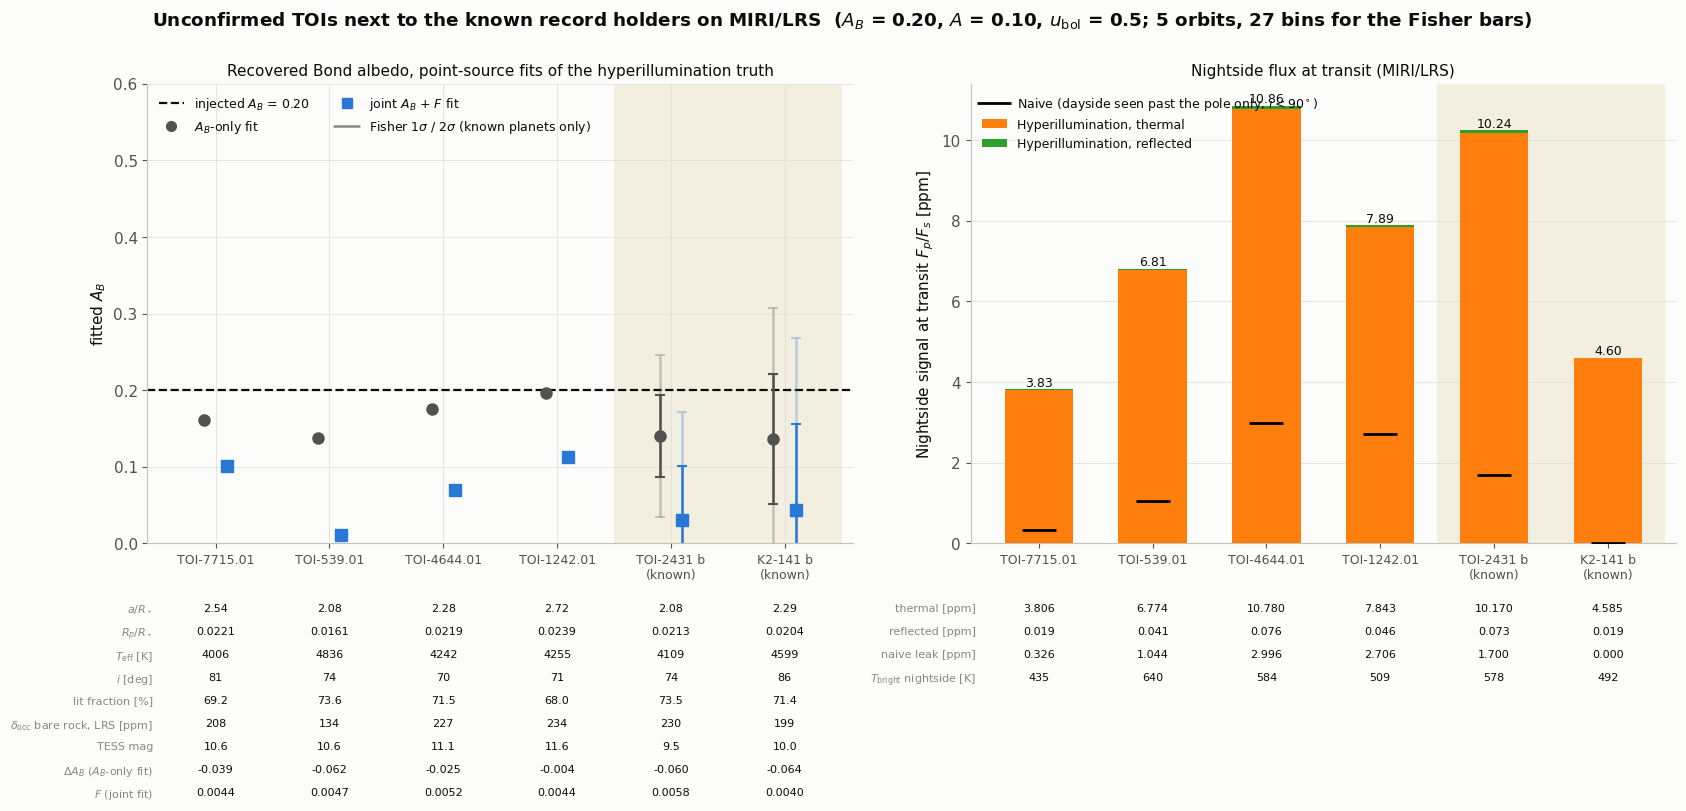

In [9]:
COMPARISON_FACE = "#f3efe0"   # tint of the comparison planets (axes in 6., column spans here)


def tag(name):
    return f"{name} (known planet, comparison)" if is_comparison[name] else f"{name} (TESS candidate)"


def plot_lrs_comparison(lrs, title=None):
    names = list(lrs)
    x = np.arange(len(names))
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(17, 8.5))

    # left: fitted A_B, A_B-only (circle) and joint (square), Fisher bars only where there is a noise level
    for k, nm in enumerate(names):
        for j, (model, marker, color) in enumerate((("naive", "o", C_NAIVE), ("naive_redist", "s", C_REDIST))):
            r, xx = lrs[nm]["fit"][model], k + (j - 0.5) * 0.2
            if "sigma_A_B" in r:
                for lev, alpha in ((2, .3), (1, 1.)):   # widest bar first (lightest), 1 sigma on top
                    ax0.errorbar(xx, r["A_B_fit"], yerr=lev * r["sigma_A_B"], fmt="none", ecolor=color, alpha=alpha, elinewidth=1.8, capsize=3.5, capthick=1.5, zorder=3)
            ax0.plot(xx, r["A_B_fit"], marker, ms=8, color=color, zorder=4)
    ax0.axhline(A_B_true, color=INK, ls="--", lw=1.6, zorder=2)
    ax0.set_ylabel(r"fitted $A_B$"); ax0.set_ylim(0., 0.6)
    ax0.set_title("Recovered Bond albedo, point-source fits of the hyperillumination truth", fontsize=11)
    ax0.legend(handles=[plt.Line2D([], [], color=INK, ls="--", lw=1.6, label=rf"injected $A_B$ = {A_B_true:.2f}"),
                        plt.Line2D([], [], marker="o", ls="none", ms=7, color=C_NAIVE, label="$A_B$-only fit"),
                        plt.Line2D([], [], marker="s", ls="none", ms=7, color=C_REDIST, label="joint $A_B$ + $F$ fit"),
                        plt.Line2D([], [], color=MUTED, lw=1.8, label=r"Fisher 1$\sigma$ / 2$\sigma$ (known planets only)")], loc="upper left", fontsize=9, ncol=2)

    # right: nightside signal at transit, hyperillumination (stacked) and the naive leak
    thermal = np.array([lrs[nm]["night"]["thermal"] for nm in names]); reflected = np.array([lrs[nm]["night"]["reflected"] for nm in names])
    ax1.bar(x, thermal, color="C1", width=.6, label="Hyperillumination, thermal", zorder=3)
    ax1.bar(x, reflected, bottom=thermal, color="C2", width=.6, label="Hyperillumination, reflected", zorder=3)
    ax1.plot(x, [lrs[nm]["night"]["naive"] for nm in names], "k_", ms=25, mew=2, label=r"Naive (dayside seen past the pole only, $i<90^\circ$)", zorder=4)
    for xi, v in zip(x, thermal + reflected): ax1.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax1.set_ylabel(r"Nightside signal at transit $F_p/F_s$ [ppm]")
    ax1.set_title(f"Nightside flux at transit ({instrument})", fontsize=11)
    ax1.legend(loc="upper left", fontsize=9); ax1.grid(axis="x", visible=False)

    # both: planet ticks, the known planets tinted
    for ax in (ax0, ax1):
        ax.set_xticks(x, [nm + ("\n(known)" if is_comparison[nm] else "") for nm in names], fontsize=9)
        ax.set_xlim(-0.6, len(names) - 0.4)
        for k, nm in enumerate(names):
            if is_comparison[nm]: ax.axvspan(k - 0.5, k + 0.5, color=COMPARISON_FACE, zorder=0, lw=0)

    # rows under the axes: geometry, observability and fit numbers (left), nightside numbers (right)
    pls = [planets[nm] for nm in names]
    rows0 = [(r"$a/R_\star$", [pl.R / pl.r2 for pl in pls], "{:.2f}"),
             (r"$R_p/R_\star$", [pl.r1 / pl.r2 for pl in pls], "{:.4f}"),
             (r"$T_{\rm eff}$ [K]", [pl.T2_eff for pl in pls], "{:.0f}"),
             (r"$i$ [deg]", [pl.incl for pl in pls], "{:.0f}"),
             ("lit fraction [%]", [100 * pl.fraction_illuminated() for pl in pls], "{:.1f}"),
             (r"$\delta_{\rm occ}$ bare rock, LRS [ppm]", [pl.approx_occ_depth(filter_lambda(instrument), A_B=A_B_true, A_g=A) for pl in pls], "{:.0f}"),
             ("TESS mag", [tmag[nm] for nm in names], "{:.1f}"),
             (r"$\Delta A_B$ ($A_B$-only fit)", [lrs[nm]["fit"]["naive"]["bias_A_B"] for nm in names], "{:+.3f}"),
             (r"$F$ (joint fit)", [lrs[nm]["fit"]["naive_redist"]["F_fit"] for nm in names], "{:.4f}")]
    rows1 = [("thermal [ppm]", thermal, "{:.3f}"), ("reflected [ppm]", reflected, "{:.3f}"),
             ("naive leak [ppm]", [lrs[nm]["night"]["naive"] for nm in names], "{:.3f}"),
             (r"$T_{\rm bright}$ nightside [K]", [lrs[nm]["night"]["T_bright"] for nm in names], "{:.0f}")]
    below = max(_param_rows(ax0, x, rows0, y0=-0.13, dy=0.05), _param_rows(ax1, x, rows1, y0=-0.13, dy=0.05))
    fig.suptitle(title or rf"Unconfirmed TOIs next to the known record holders on {instrument}  ($A_B$ = {A_B_true:.2f}, $A$ = {A:.2f}, $u_{{\rm bol}}$ = {u_bol:g}; {n_orbits} orbits, {n_bins} bins for the Fisher bars)", y=1.0, fontweight="bold")
    fig.tight_layout()
    fig.subplots_adjust(bottom=min(0.6, 0.1 + below * ax0.get_position().height))   # room for the rows (axes fraction -> figure fraction)
    return fig, (ax0, ax1)


fig, axs = plot_lrs_comparison(lrs)
plt.show()

## 6. Per planet

`analyse_planet` gives for one planet: the `PlanetParams` line for `targets.register_planet` (or a row of `inputs/planets/curated_planets.csv`); `summary()`; the MIRI/LRS phase curve with the best point-source fits and their residuals; the retrieved $A_B$ per JWST instrument (`instrument_retrievals`, after Ramirez et al. 2026 Fig. 4); and the nightside flux per instrument (as in `forward_model/06_nightside_temperature.ipynb` §3).

What to look for: how a candidate's bias changes with the band, and whether its nightside flux reaches the ppm level anywhere.

In [10]:
# comments of the CUSTOM lines: the provenance of each candidate; the comparison planets echo their existing entries
notes = {}
for p in CANDIDATES:
    d = derived(p)
    notes[p["name"]] = f"TESS {p['disposition']} (TIC {p['tic']}), ExoFOP {EXOFOP_DATE}, TIC v8 host; a/R* from rho_star = {d['a_over_r2']:.2f} +- {d['a_over_r2_err']:.2f}; r1 from the depth; incl from T14 (b = {d['b']:.2f}); 07_tess_candidates.ipynb"
for nm in comparison:
    notes[nm] = "as returned by hi_planets_by_name (already curated or in the archive)"


def mark_comparison(fig, name):
    '''Tint the axes of a comparison planet's figure.'''
    if is_comparison[name]:
        for a_ in fig.axes: a_.set_facecolor(COMPARISON_FACE)


def plot_truth_and_fits(cfg, A_B_true, fit, title=None, **kw):
    '''plot_fit_vs_truth without the mock data: truth and best fits (left), residuals before and after absorbing the bias (right), for a planet without a noise level.'''
    t_, truth = model_pcurve(cfg, "hyperillum", A_B_true, **kw)
    naive_0 = model_pcurve(cfg, "naive", A_B_true, **kw)[1]
    curves = []
    for model, label, ls, color in (("naive", "best $A_B$-only fit", "--", C_NAIVE), ("naive_redist", "best joint fit", "-.", C_REDIST)):
        f = fit[model]
        y = model_pcurve(cfg, model, f["A_B_fit"], F=f.get("F_fit"), **kw)[1]
        tag_ = f"$A_B$ = {f['A_B_fit']:.3f}" + (f", $F$ = {f['F_fit']:.4f}" if "F_fit" in f else "")
        curves.append((y + (truth - y).mean(), f"{label} ({tag_})", ls, color))   # the fitted baseline (free_offset)
    fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
    ax[0].plot(t_ * 24., truth, lw=1.2, color=C_HI, label="hyperillumination (truth)")
    for y, label, ls, color in curves: ax[0].plot(t_ * 24., y, lw=1.2, ls=ls, color=color, label=label)
    ax[0].set_xlabel("time [h]"); ax[0].set_ylabel(r"$F_p/F_s$ [ppm]"); ax[0].set_title("truth and best fits (no noise level for a candidate)")
    ax[1].axhline(0., color=AXIS, lw=.8)
    ax[1].plot(t_ * 24., truth - naive_0, lw=1.2, color=C_HI, label=rf"truth $-$ naive at the true $A_B$ = {A_B_true:.2f}")
    for y, label, ls, color in curves: ax[1].plot(t_ * 24., truth - y, lw=1.2, color=color, label=f"truth $-$ {label.split(' (')[0]} (irreducible)")
    ax[1].set_xlabel("time [h]"); ax[1].set_ylabel("residual [ppm]"); ax[1].set_title("residual before and after absorbing the bias")
    for a_ in ax: a_.legend(fontsize=9)
    fig.suptitle(title or rf"{cfg.planet.name}: $a/R_\star$ = {cfg.planet.R / cfg.planet.r2:.2f}", y=1.02)
    fig.tight_layout()
    return fig, ax


def nightside_table(planet):
    '''Planet signal at transit per band (nightside_flux; hyperillumination vs naive, thermal / reflected split, brightness temperature of the thermal part), as in 06_nightside_temperature.ipynb section 3.'''
    runs = [(ins, m, "flux") for ins in night_instruments for m in ("hyperillum", "naive")] + [(ins, "hyperillum", "temperature") for ins in night_instruments]
    out = Parallel(n_jobs=-1, backend="loky")(delayed(nightside_flux)(planet, filter_lambda(ins), m, unit=unit, filter_path=filter_loc(ins), u_bol=u_bol, A_B=A_B_true, A=A) for ins, m, unit in runs)
    res = dict(zip(runs, out))
    return pd.DataFrame([{"instrument": ins, "band [µm]": "{:.1f}-{:.1f}".format(*(1e6 * filter_lambda(ins))),
                          "HI thermal [ppm]": res[ins, "hyperillum", "flux"][0], "HI reflected [ppm]": res[ins, "hyperillum", "flux"][1],
                          "HI total [ppm]": sum(res[ins, "hyperillum", "flux"]), "naive total [ppm]": sum(res[ins, "naive", "flux"]),
                          "HI nightside T_bright [K]": res[ins, "hyperillum", "temperature"]} for ins in night_instruments]).set_index("instrument")


def plot_nightside_bars(night_tab, name):
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(night_tab))
    ax.bar(x, night_tab["HI thermal [ppm]"], color="C1", label="Hyperillumination, thermal")
    ax.bar(x, night_tab["HI reflected [ppm]"], bottom=night_tab["HI thermal [ppm]"], color="C2", label="Hyperillumination, reflected")
    ax.plot(x, night_tab["naive total [ppm]"], "k_", ms=25, mew=2, label=r"Naive (dayside seen past the pole only, $i<90^\circ$)")
    for xi, v in zip(x, night_tab["HI total [ppm]"]): ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, [f"{ins}\n{b} µm" for ins, b in zip(night_tab.index, night_tab["band [µm]"])], rotation=30, ha="right", fontsize=9)
    ax.set_ylabel(r"Nightside signal at transit $F_p/F_s$ [ppm]")
    ax.set_title(f"{tag(name)}: nightside flux at transit ($A_B$ = {A_B_true:.2f}, $A$ = {A:.2f})")
    ax.legend(loc="upper left"); ax.grid(axis="y", alpha=.3)
    fig.tight_layout()
    return fig, ax


def analyse_planet(name):
    '''The items of 6. for one planet, reusing the MIRI/LRS fits of 5.; returns its tables for the overview of 7.'''
    pl, levels, fit, known = planets[name], sigma_levels[name], lrs[name]["fit"], is_comparison[name]
    print(custom_entry_line(pl, notes[name]), "\n")
    pl.summary(eff_wavelength_range=filter_lambda(instrument))

    # 3. MIRI/LRS: truth, best point-source fits, residuals
    cfg_p = replace(cfg, planet=pl, sigma_1min=levels[instrument])
    head = rf"{tag(name)}: $a/R_\star$ = {pl.R / pl.r2:.2f}, $T_{{\rm eff}}$ = {pl.T2_eff:.0f} K, $P$ = {24 * pl.period:.2f} h, $i$ = {pl.incl:.0f}°  ({instrument}"
    if known: fig, ax = plot_fit_vs_truth(cfg_p, A_B_true, fit, **kw, title=head + rf", {cfg_p.n_orbits} orbits, $\sigma_{{\rm bin}}$ = {cfg_p.sigma_bin:.0f} ppm)")
    else:     fig, ax = plot_truth_and_fits(cfg_p, A_B_true, fit, **kw, title=head + ")")
    mark_comparison(fig, name); plt.show()
    n_, j_ = fit["naive"], fit["naive_redist"]
    print(f"A_B-only: A_B {A_B_true:.3f} -> {n_['A_B_fit']:.3f} ({100 * n_['bias_A_B'] / A_B_true:+.1f} %), residual rms {n_['rms']:.2f} ppm"
          + (f", Fisher sigma {n_['sigma_A_B']:.3f}, |bias|/sigma = {abs(n_['bias_A_B']) / n_['sigma_A_B']:.2f}, misfit sqrt(chi2) = {np.sqrt(n_['chi2']):.2f} sigma" if known else ""))
    print(f"joint:    A_B {A_B_true:.3f} -> {j_['A_B_fit']:.3f} ({100 * j_['bias_A_B'] / A_B_true:+.1f} %), F = {j_['F_fit']:.4f}, residual rms {j_['rms']:.2f} ppm"
          + (f", Fisher sigma {j_['sigma_A_B']:.3f}, spurious F at sqrt(dchi2_F) = {np.sqrt(max(n_['chi2'] - j_['chi2'], 0.)):.2f} sigma" if known else ""))

    # 4. retrieved A_B per instrument (A_B-only fit); error bars, verdicts and sigmas only for a known planet
    tab = instrument_retrievals(cfg_p, pl, retrieval_instruments, A_B_true, sigma_1min=levels, bounds=bounds, **kw)
    fig, ax = plot_instrument_retrievals(tab, sigma_levels=(1, 2) if known else (), title=f"{tag(name)}: $A_B$-only fit" + (f"  ({cfg_p.n_orbits} orbits per instrument)" if known else "  (no noise level: fitted values only)"))
    mark_comparison(fig, name); plt.show()
    cols = ["instrument", "sigma_1min", "A_B_fit", "bias_A_B", "sigma_A_B", "bias_sigma", "verdict"] if known else ["instrument", "A_B_fit", "bias_A_B"]
    print(tab[cols].to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))

    # 5. nightside flux per instrument
    night = nightside_table(pl)
    fig, ax = plot_nightside_bars(night, name)
    mark_comparison(fig, name); plt.show()
    print(night.round(3).to_string())

    get_reusable_executor().shutdown(wait=True)   # recycle the loky workers between planets (SPIDERMAN's allocator growth accumulates in reused workers)
    return dict(instruments=tab, nightside=night)


results = {}

### 6.1 TOI-7715.01

"TOI-7715.01": PlanetParams(name="TOI-7715.01", period=0.3236320, incl=80.8, ecc=0.0, w=90.0, r1=0.02209, r2=1.0, R=2.542, T2_eff=4006.0, a_AU=0.00791, T14=0.947, logg=4.59, feh=+0.00),   # TESS PC (TIC 200001699), ExoFOP 2026-10-20, TIC v8 host; a/R* from rho_star = 2.54 +- 0.24; r1 from the depth; incl from T14 (b = 0.41); 07_tess_candidates.ipynb 

=== TOI-7715.01 ===
rp = r1/r2           = 0.0221
a  = R/r2            = 2.542
terminator_penumbra  = 66.3 deg
terminator_nightside = 112.6 deg
fraction_illuminated = 69.2 %  (fully illuminated: 29.9 %, penumbra: 39.3 %)
substellar_boost     = 1.76076 % (insolation), 0.43731 % (temperature)
approx_occ_depth     = 200.4 ppm


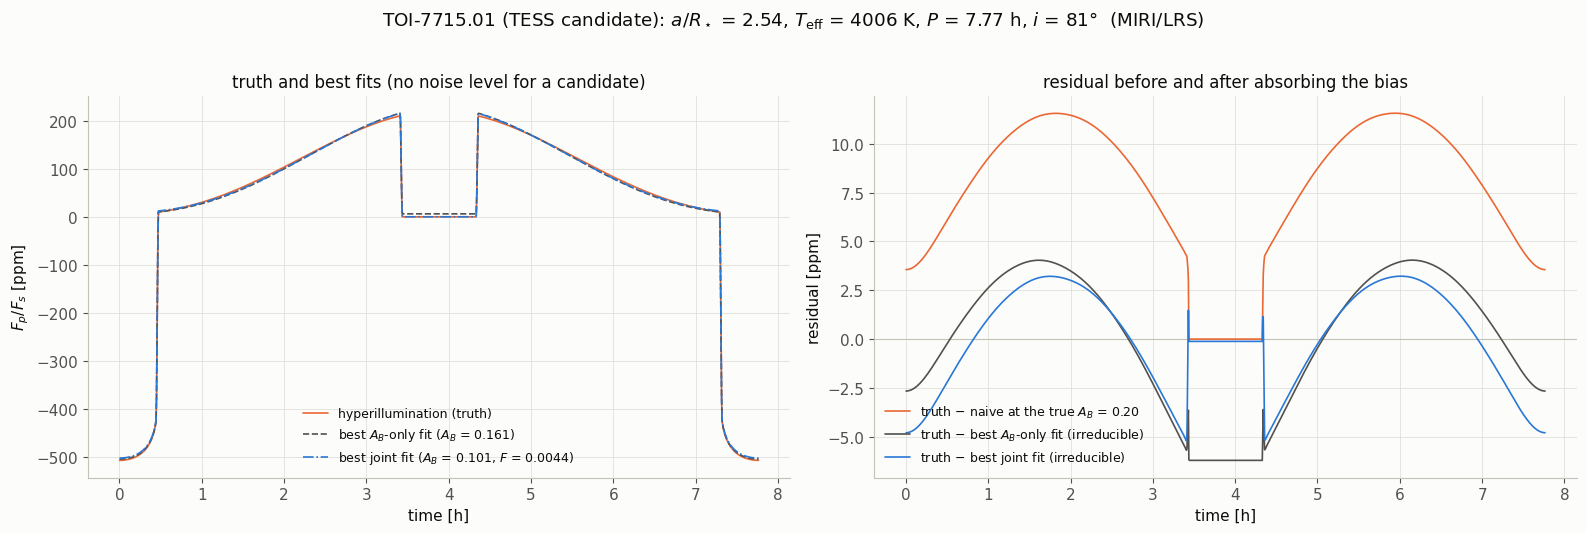

A_B-only: A_B 0.200 -> 0.161 (-19.4 %), residual rms 3.39 ppm
joint:    A_B 0.200 -> 0.101 (-49.5 %), F = 0.0044, residual rms 2.45 ppm


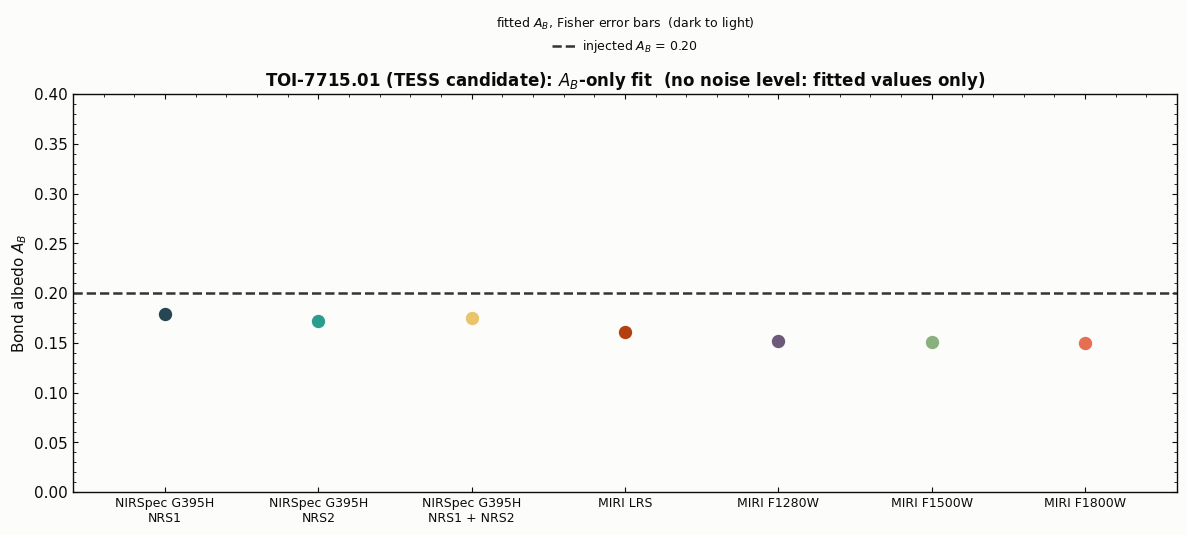

                                     instrument  A_B_fit  bias_A_B
                        JWST_NIRSpec.G395H_NRS1   0.1787  -0.02131
                        JWST_NIRSpec.G395H_NRS2   0.1721  -0.02788
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2   0.1752  -0.02484
                                       MIRI/LRS   0.1613  -0.03871
                                    MIRI/F1280W   0.1522  -0.04784
                                    MIRI/F1500W   0.1508  -0.04919
                                    MIRI/F1800W   0.1497  -0.05027


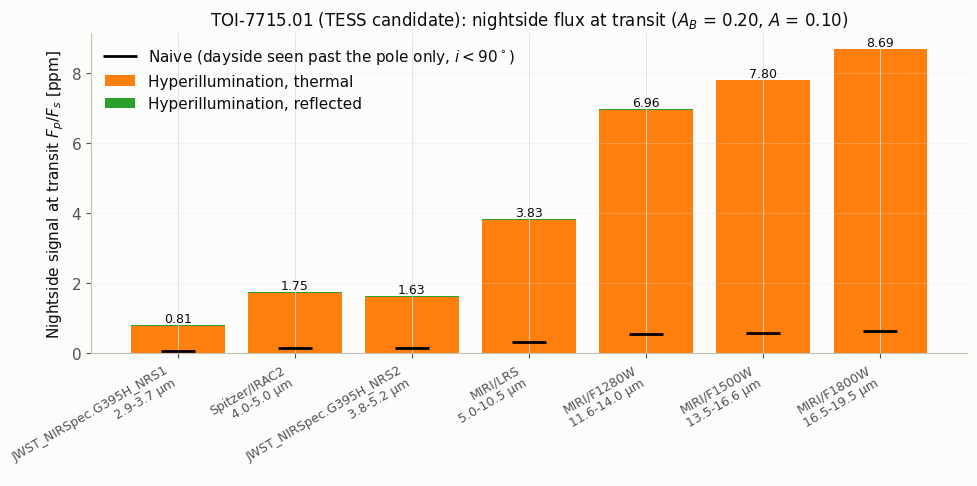

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             0.789               0.019           0.808              0.077                    617.433
Spitzer/IRAC2              4.0-5.0             1.730               0.019           1.750              0.163                    546.376
JWST_NIRSpec.G395H_NRS2    3.8-5.2             1.609               0.019           1.628              0.152                    550.668
MIRI/LRS                  5.0-10.5             3.806               0.019           3.826              0.326                    434.909
MIRI/F1280W              11.6-14.0             6.937               0.019           6.956              0.537                    342.702
MIRI/F1500W              13.5-16.6             7.780   

In [11]:
results["TOI-7715.01"] = analyse_planet("TOI-7715.01")

### 6.2 TOI-539.01

"TOI-539.01": PlanetParams(name="TOI-539.01", period=0.3096060, incl=74.3, ecc=0.0, w=90.0, r1=0.01605, r2=1.0, R=2.082, T2_eff=4836.0, a_AU=0.00787, T14=1.030, logg=4.45, feh=+0.00),   # TESS PC (TIC 238004786), ExoFOP 2026-10-20, TIC v8 host; a/R* from rho_star = 2.08 +- 0.55; r1 from the depth; incl from T14 (b = 0.56); 07_tess_candidates.ipynb 

=== TOI-539.01 ===
rp = r1/r2           = 0.0161
a  = R/r2            = 2.082
terminator_penumbra  = 60.8 deg
terminator_nightside = 118.2 deg
fraction_illuminated = 73.6 %  (fully illuminated: 25.6 %, penumbra: 48.0 %)
substellar_boost     = 1.56020 % (insolation), 0.38779 % (temperature)
approx_occ_depth     = 128.5 ppm


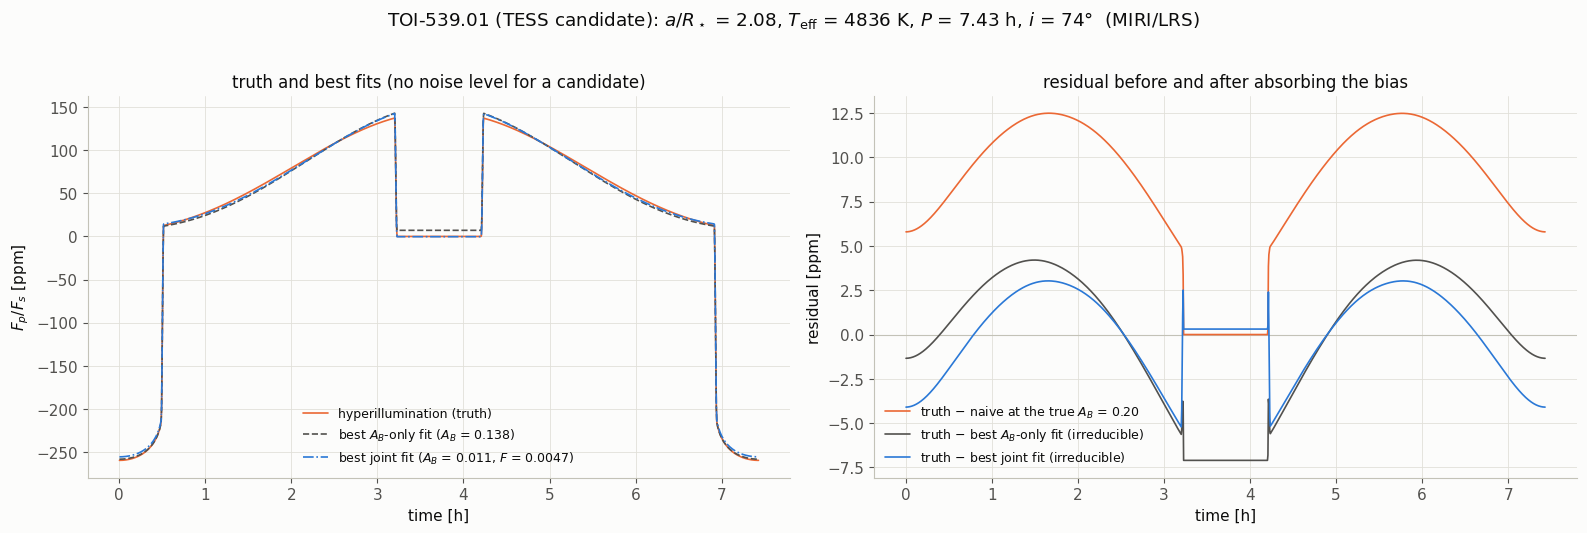

A_B-only: A_B 0.200 -> 0.138 (-31.2 %), residual rms 3.70 ppm
joint:    A_B 0.200 -> 0.011 (-94.6 %), F = 0.0047, residual rms 2.22 ppm


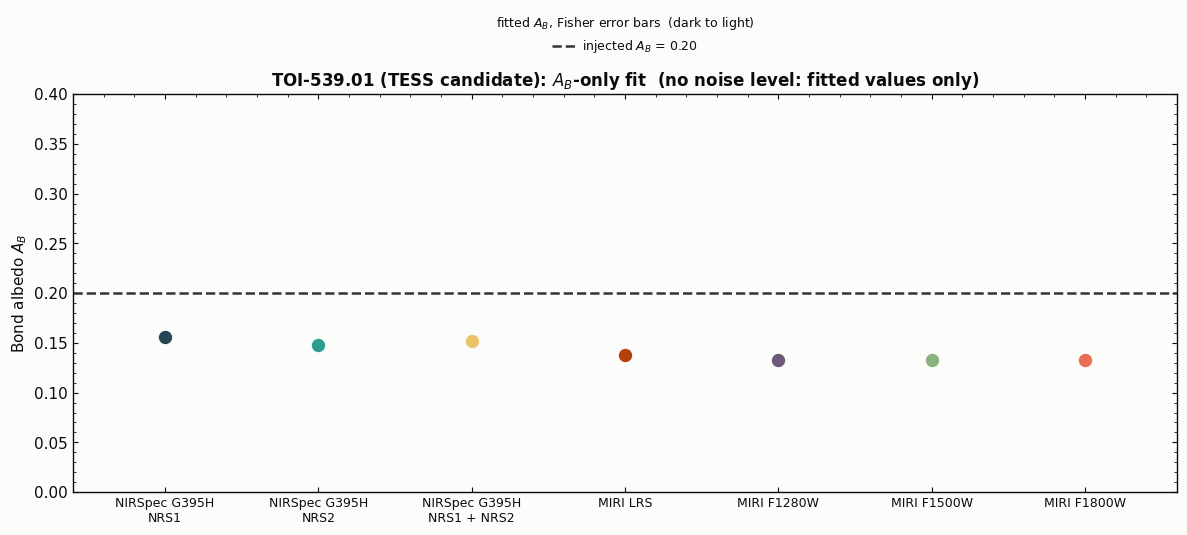

                                     instrument  A_B_fit  bias_A_B
                        JWST_NIRSpec.G395H_NRS1   0.1561  -0.04387
                        JWST_NIRSpec.G395H_NRS2   0.1476  -0.05243
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2   0.1516  -0.04841
                                       MIRI/LRS   0.1375  -0.06245
                                    MIRI/F1280W   0.1326  -0.06736
                                    MIRI/F1500W   0.1326  -0.06736
                                    MIRI/F1800W    0.133  -0.06699


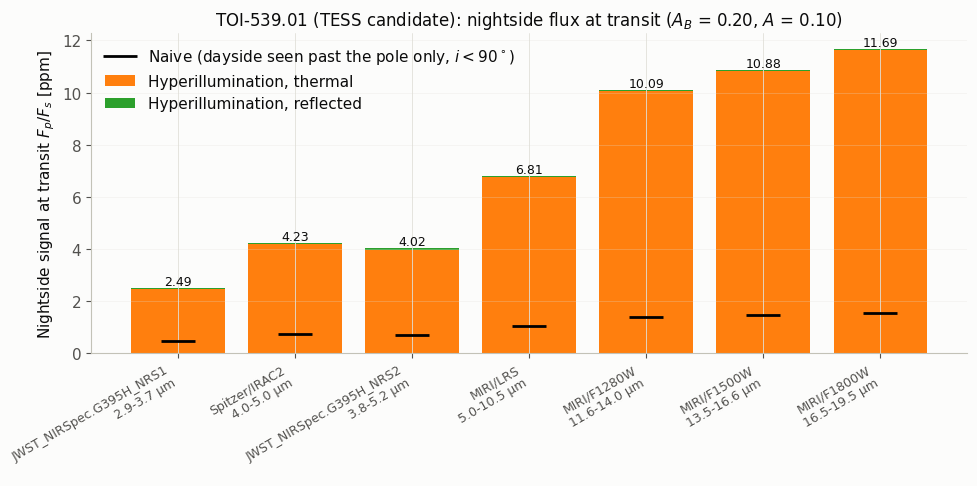

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             2.451               0.041           2.492              0.468                    872.269
Spitzer/IRAC2              4.0-5.0             4.185               0.041           4.226              0.727                    775.695
JWST_NIRSpec.G395H_NRS2    3.8-5.2             3.978               0.041           4.019              0.696                    782.962
MIRI/LRS                  5.0-10.5             6.774               0.041           6.815              1.044                    639.513
MIRI/F1280W              11.6-14.0            10.051               0.041          10.092              1.396                    516.300
MIRI/F1500W              13.5-16.6            10.836   

In [12]:
results["TOI-539.01"] = analyse_planet("TOI-539.01")

### 6.3 TOI-4644.01

"TOI-4644.01": PlanetParams(name="TOI-4644.01", period=0.3181850, incl=69.9, ecc=0.0, w=90.0, r1=0.02191, r2=1.0, R=2.275, T2_eff=4242.2, a_AU=0.00794, T14=0.762, logg=4.51, feh=-0.11),   # TESS PC (TIC 387423096), ExoFOP 2026-10-20, TIC v8 host; a/R* from rho_star = 2.28 +- 0.22; r1 from the depth; incl from T14 (b = 0.78); 07_tess_candidates.ipynb 

=== TOI-4644.01 ===
rp = r1/r2           = 0.0219
a  = R/r2            = 2.275
terminator_penumbra  = 63.3 deg
terminator_nightside = 115.5 deg
fraction_illuminated = 71.5 %  (fully illuminated: 27.5 %, penumbra: 44.0 %)
substellar_boost     = 1.95409 % (insolation), 0.48498 % (temperature)
approx_occ_depth     = 218.1 ppm


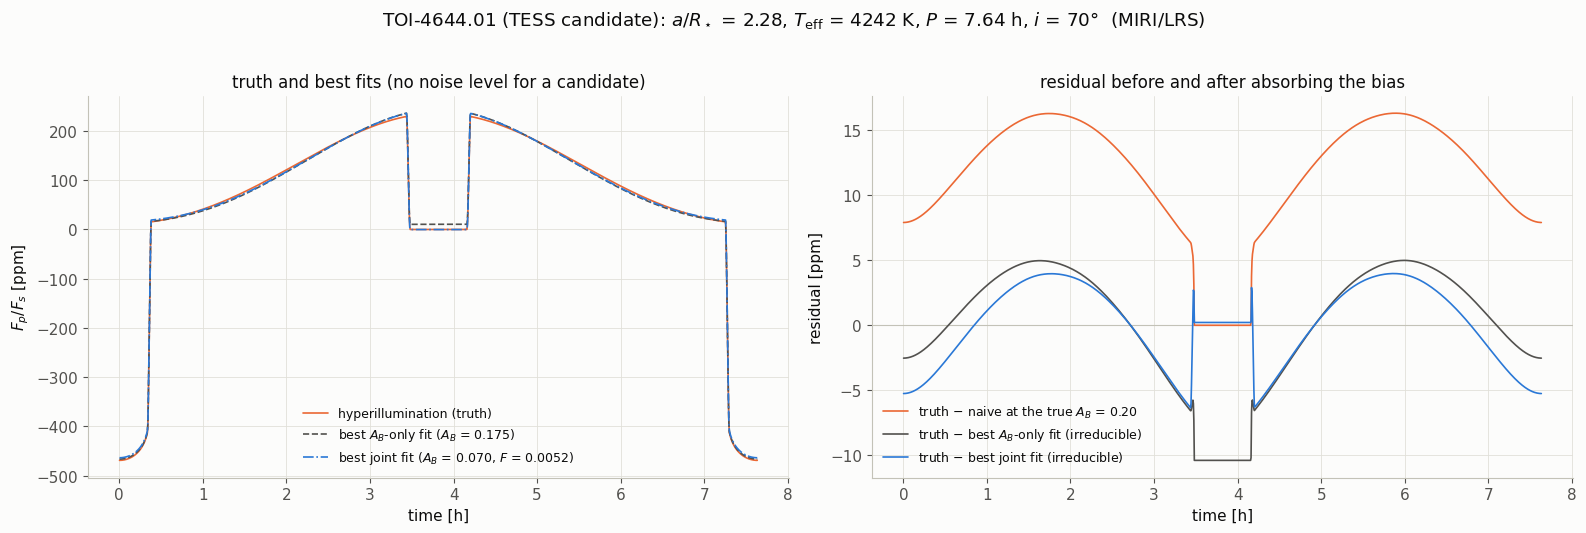

A_B-only: A_B 0.200 -> 0.175 (-12.6 %), residual rms 4.48 ppm
joint:    A_B 0.200 -> 0.070 (-65.2 %), F = 0.0052, residual rms 2.97 ppm


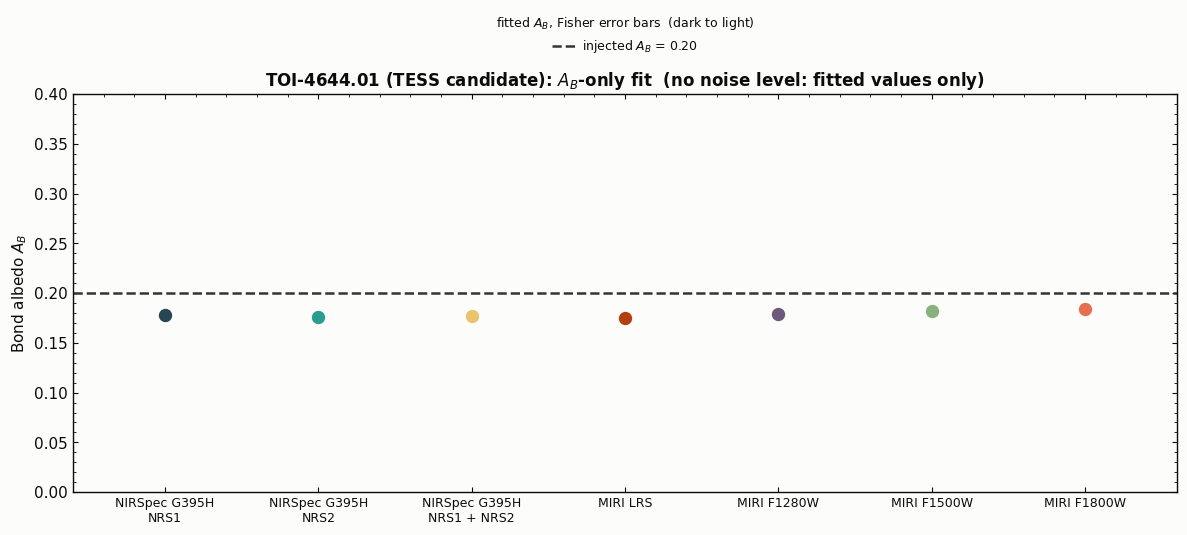

                                     instrument  A_B_fit  bias_A_B
                        JWST_NIRSpec.G395H_NRS1   0.1785  -0.02147
                        JWST_NIRSpec.G395H_NRS2   0.1756  -0.02437
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2    0.177  -0.02303
                                       MIRI/LRS   0.1748   -0.0252
                                    MIRI/F1280W   0.1795  -0.02053
                                    MIRI/F1500W   0.1817  -0.01834
                                    MIRI/F1800W   0.1842   -0.0158


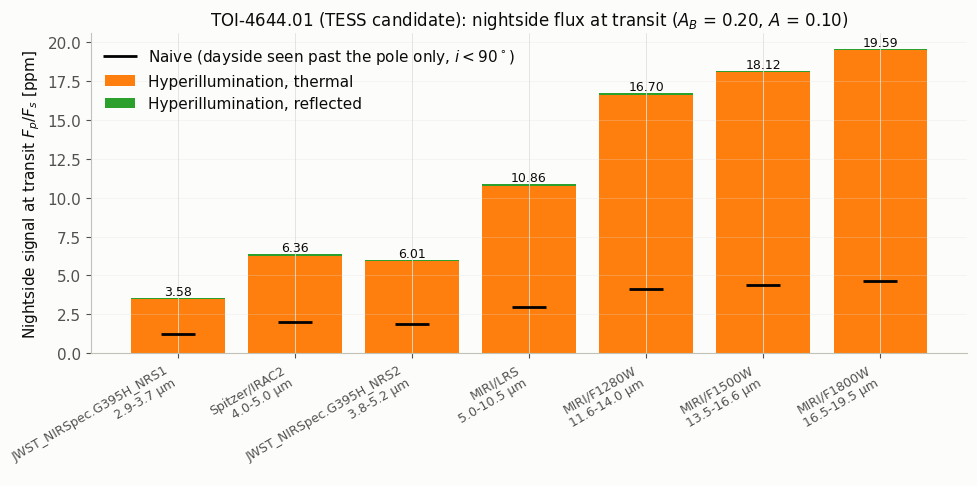

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             3.500               0.076           3.576              1.235                    802.421
Spitzer/IRAC2              4.0-5.0             6.279               0.076           6.355              1.994                    713.208
JWST_NIRSpec.G395H_NRS2    3.8-5.2             5.931               0.076           6.007              1.899                    719.665
MIRI/LRS                  5.0-10.5            10.780               0.076          10.856              2.996                    583.726
MIRI/F1280W              11.6-14.0            16.621               0.076          16.697              4.126                    468.058
MIRI/F1500W              13.5-16.6            18.047   

In [13]:
results["TOI-4644.01"] = analyse_planet("TOI-4644.01")

### 6.4 TOI-1242.01

"TOI-1242.01": PlanetParams(name="TOI-1242.01", period=0.3814850, incl=70.7, ecc=0.0, w=90.0, r1=0.02387, r2=1.0, R=2.717, T2_eff=4255.0, a_AU=0.00897, T14=0.565, logg=4.56, feh=+0.00),   # TESS PC (TIC 198212955), ExoFOP 2026-10-20, TIC v8 host; a/R* from rho_star = 2.72 +- 0.24; r1 from the depth; incl from T14 (b = 0.90); 07_tess_candidates.ipynb 

=== TOI-1242.01 ===
rp = r1/r2           = 0.0239
a  = R/r2            = 2.717
terminator_penumbra  = 67.9 deg
terminator_nightside = 111.1 deg
fraction_illuminated = 68.0 %  (fully illuminated: 31.2 %, penumbra: 36.8 %)
substellar_boost     = 1.78075 % (insolation), 0.44225 % (temperature)
approx_occ_depth     = 226.0 ppm


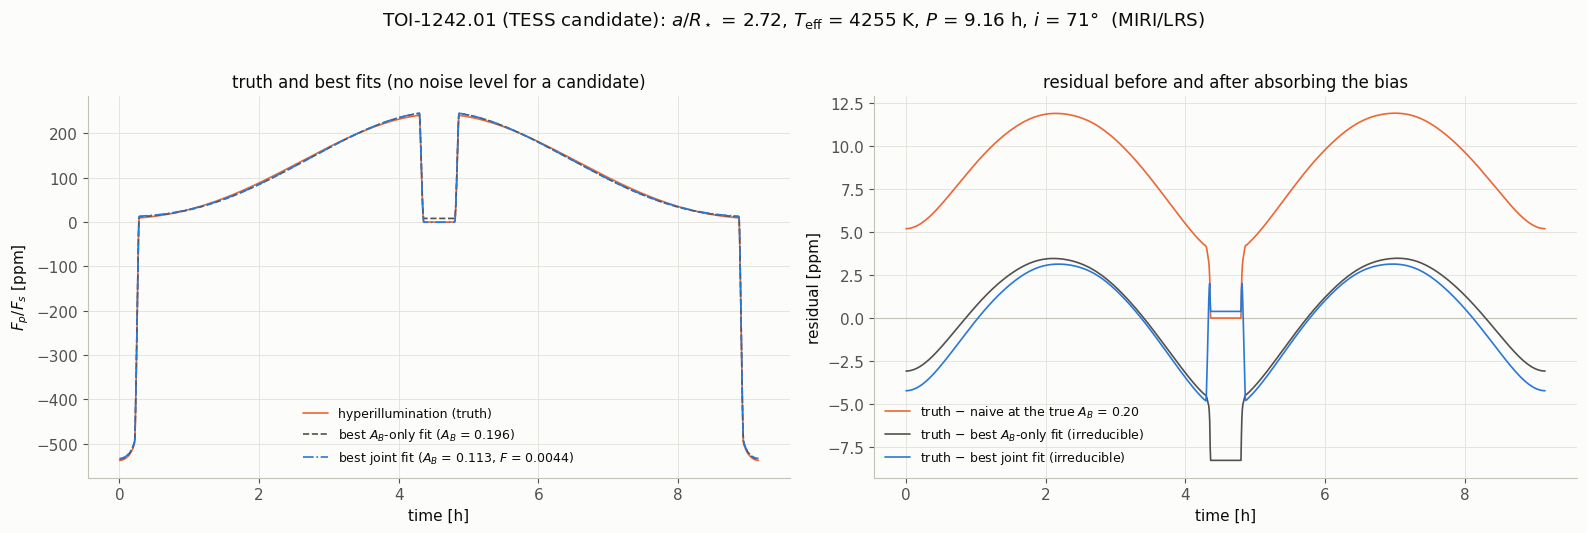

A_B-only: A_B 0.200 -> 0.196 (-1.8 %), residual rms 3.03 ppm
joint:    A_B 0.200 -> 0.113 (-43.6 %), F = 0.0044, residual rms 2.40 ppm


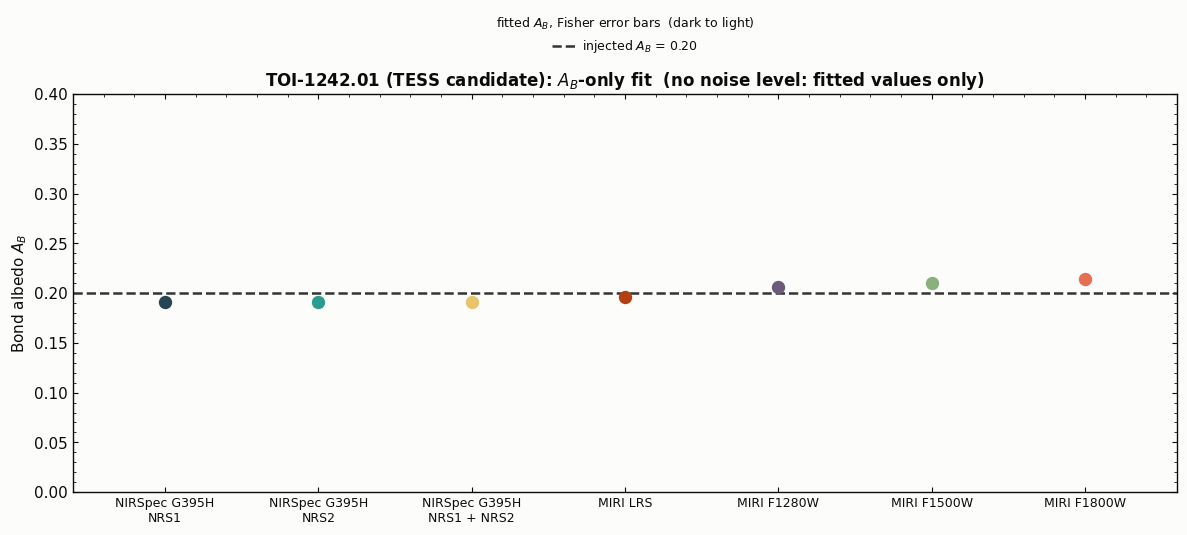

                                     instrument  A_B_fit  bias_A_B
                        JWST_NIRSpec.G395H_NRS1   0.1909 -0.009069
                        JWST_NIRSpec.G395H_NRS2   0.1915 -0.008514
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2   0.1912 -0.008764
                                       MIRI/LRS   0.1963 -0.003698
                                    MIRI/F1280W   0.2065  0.006532
                                    MIRI/F1500W     0.21  0.009971
                                    MIRI/F1800W   0.2138   0.01375


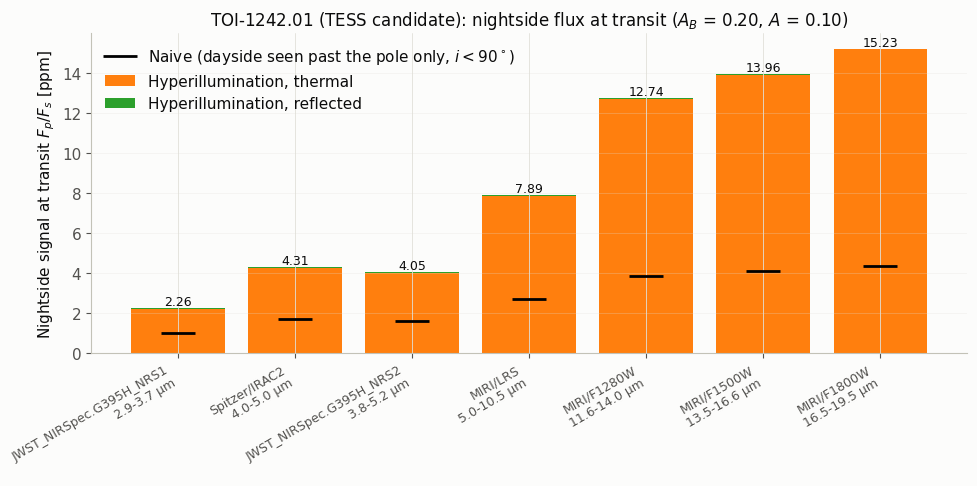

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             2.218               0.046           2.264              0.990                    719.486
Spitzer/IRAC2              4.0-5.0             4.261               0.046           4.307              1.700                    635.116
JWST_NIRSpec.G395H_NRS2    3.8-5.2             4.004               0.046           4.050              1.611                    640.852
MIRI/LRS                  5.0-10.5             7.843               0.046           7.889              2.706                    509.257
MIRI/F1280W              11.6-14.0            12.697               0.046          12.743              3.869                    400.713
MIRI/F1500W              13.5-16.6            13.918   

In [14]:
results["TOI-1242.01"] = analyse_planet("TOI-1242.01")